# Báo cáo Project
Lớp TTNT-162297, Nhóm G08

## 1. Thông tin chung

> Thêm khối trích dẫn



### Thành viên
- Nguyễn Thái An 202416110
- Trần Bình Minh 202416294
- Nguyễn Thanh Hải 202416192
- Bùi Hoàng Tú 202416378

### Lịch thực hiện
- W2: Đăng ký nhóm
- W3-4: Đề xuất project (03/10)
- W08: Báo cáo tiến độ giữa kỳ (24/10)
- W15: Hoàn thành và gửi báo cáo project (12/12)
- W16-18: Trình bày project, Q&A

## 2. Đề xuất project (W3)

### Bài toán
Nghiên cứu và tối ưu hóa bài toán giải và sinh hình thế Sudoku dạng CSP (Constraint Satisfaction Problem). Xây dựng giải pháp cho phép nhận diện tính hợp lệ của cấu hình người dùng đánh trước vài ô ngẫu nhiên và tự động sinh ra các hình thế hoàn chỉnh. Đánh giá thuật toán bằng nhiều metric và giao diện trực quan.

### Phương pháp dự kiến
Xây dựng mô hình 4 cấp độ: Naive Backtracking $\to$ Forward Checking $\to$ MRV/Degree Heuristic $\to$ AC-3 kết hợp Randomized Candidate Selection.

### Phân công
- Nguyễn Thái An: Phân tích các thuật toán và triển khai
- Trần Bình Minh: Đánh giá các thuật toán theo các metrics (chưa rõ các chỉ số)
- Nguyễn Thanh Hải: Phân tích các thuật toán và triển khai
- Bùi Hoàng Tú: Dashboard & Trực quan hóa Tương tác

## 3. Tiến độ giữa kỳ (W8)

### Phương pháp hiện tại
So với đề xuất ban đầu ở tuần 3 (xây dựng tuần tự 4 cấp độ cố định: Naive Backtracking $\to$ Forward Checking $\to$ MRV/Degree $\to$ AC-3 kết hợp Randomized Candidate Selection, kèm bài toán sinh đề), hiện tại nhóm điều chỉnh theo hướng thiết kế mô-đun trên cùng một bộ khung CSP. Lý do là các kỹ thuật trong bài giảng thực chất giải quyết những khâu khác nhau của quá trình tìm kiếm: chọn biến, chọn giá trị, lan truyền ràng buộc và xử lý khi gặp ngõ cụt. Nếu tách cứng thành 4 mức thì rất khó bật/tắt từng thành phần để quan sát vai trò riêng của mỗi kỹ thuật. Ngoài ra, thay vì đưa yếu tố ngẫu nhiên vào bước chọn ứng viên của DFS, nhóm tách hẳn một nhánh tìm kiếm cục bộ (Local Search - Min-Conflicts) để đối chiếu với tìm kiếm hệ thống theo chiều sâu. Ở giai đoạn giữa kỳ, chương trình tập trung vào kiểm tra tính hợp lệ của cấu hình đầu vào, giải Sudoku 9x9 và trực quan hóa từng bước; phần tự động sinh hình thế hoàn chỉnh và kiểm tra nghiệm duy nhất chưa triển khai.

**Mô hình hóa bài toán theo CSP và cách biểu diễn ràng buộc nhị phân:**
- *Biến và miền giá trị:* Bàn Sudoku $9\times 9$ gồm $81$ biến rời rạc $X_{(r,c)}$ với $r, c \in \{0..8\}$. Các ô cho trước của đề bài được đưa vào tập `locked_cells` và có miền đơn trị $D(X_{(r,c)}) = [v_0]$; các ô trống có miền ban đầu $D(X_{(r,c)}) \subseteq \{1..9\}$ sau khi lọc bỏ các giá trị trùng trực tiếp với đề bài.
- *Chuyển về ràng buộc nhị phân (Binary Constraints):* Về mặt toán học, mỗi hàng, mỗi cột và mỗi khối $3\times 3$ đều mang một ràng buộc toàn cục $\text{AllDifferent}(X_1, \dots, X_9)$. Trong chương trình, mỗi ràng buộc 9 ngôi này được phân rã tương đương thành $\binom{9}{2} = 36$ ràng buộc nhị phân $X_i \neq X_j$. Hai ô bất kỳ $(r,c)$ và $(a,b)$ (với $(a,b) \neq (r,c)$) có ràng buộc nhị phân khi và chỉ khi thỏa ít nhất một trong ba điều kiện: cùng hàng ($a = r$), cùng cột ($b = c$), hoặc cùng khối $3\times 3$ ($\lfloor a/3 \rfloor = \lfloor r/3 \rfloor$ và $\lfloor b/3 \rfloor = \lfloor c/3 \rfloor$).
- *Cấu trúc dữ liệu đồ thị ràng buộc (`peers`):* Khi khởi tạo bộ giải, chương trình dựng sẵn từ điển kề `self.peers[(r, c)]` lưu tập hợp (`set`) tất cả các ô có ràng buộc nhị phân với $(r,c)$. Nhờ dùng `set`, các ô vừa cùng hàng/cột vừa cùng khối $3\times 3$ được tự động khử trùng lặp, nên mỗi biến có chính xác $8 + 8 + 4 = 20$ biến láng giềng (`peers`). Toàn bộ bàn cờ tạo thành đồ thị ràng buộc 20-chính quy gồm $81$ đỉnh, $\frac{81 \times 20}{2} = 810$ cạnh vô hướng $X_i \neq X_j$ (tương ứng $1620$ cung có hướng $(X_i \to X_j)$ khi xét lan truyền AC-3). Cách biểu diễn này bám sát đồ thị ràng buộc trong bài giảng và cho phép cài đặt thống nhất việc kiểm tra hợp lệ `is_safe`, thu hẹp miền giá trị cũng như đếm xung đột.

**Các kỹ thuật đang sử dụng, lý do lựa chọn, ưu/nhược điểm và thủ thuật triển khai:**

1. **Backtracking Search (DFS - Tìm kiếm quay lui):**
   - *Lý do sử dụng:* Thay vì sinh toàn bộ bảng rồi mới kiểm tra (Generate and Test) dẫn tới số trạng thái $O(9^n)$ quá lớn, Backtracking gán lần lượt từng ô và kiểm tra ràng buộc ngay sau mỗi phép gán để cắt sớm các nhánh sai. Đây là khung tìm kiếm nền tảng cho các kỹ thuật cải tiến phía sau.
   - *Ưu điểm:* Đảm bảo tính đầy đủ và đúng đắn trên miền hữu hạn (nếu đề có nghiệm và đủ thời gian thì tìm được nghiệm; nếu duyệt hết không gian mà không có lời giải thì kết luận được đề vô nghiệm), đồng thời dễ kết hợp với heuristics và inference.
   - *Nhược điểm:* Nếu chỉ dùng Backtracking thuần (chọn ô tuần tự, không thu hẹp miền của các ô lân cận) thì phát hiện mâu thuẫn muộn, dễ lặp lại cùng một lỗi ở nhiều nhánh và số lần quay lui tăng rất nhanh trên các đề nhiều ô trống.
   - *Thủ thuật triển khai:* Thay vì viết nhiều hàm đệ quy rời rạc cho từng biến thể (`solve_naive`, `solve_fc`, `solve_mac`,...), nhóm thiết kế duy nhất một hàm đệ quy khung `backtrack()` theo mẫu **Template Method kết hợp cờ cấu hình (Flags)**. Hàm khung chia rõ 4 bước chuẩn: chọn biến $\to$ sắp thứ tự giá trị $\to$ gán và chạy suy diễn $\to$ khôi phục trạng thái (`deepcopy` miền giá trị và tập nguyên nhân tại một điểm duy nhất trước khi thử số) khi quay lui.

2. **Heuristics chọn biến: MRV (Minimum Remaining Values) kết hợp Degree Heuristic:**
   - *Lý do sử dụng:* Trong quay lui, thứ tự chọn biến ảnh hưởng trực tiếp tới độ rộng của cây tìm kiếm. Nhóm dùng MRV để ưu tiên ô có ít giá trị hợp lệ nhất (biến bị ràng buộc chặt nhất); khi có nhiều ô cùng số lượng giá trị hợp lệ ít nhất thì dùng Degree Heuristic để ưu tiên ô có nhiều ô liên quan chưa gán nhất.
   - *Ưu điểm:* Áp dụng nguyên lý "fail-first" (phát hiện nhánh sai càng sớm càng tốt), giảm hệ số phân nhánh ngay từ các tầng trên nên thường giảm mạnh số phép gán và số lần quay lui so với chọn ô theo thứ tự hàng/cột cố định.
   - *Nhược điểm:* Mỗi bước đệ quy phải quét các ô trống và tính số giá trị hợp lệ/số láng giềng chưa gán. Với những đề rất dễ hoặc khi không kết hợp cắt miền, chi phí tính heuristic ở mỗi nút vẫn phát sinh đều đặn.
   - *Thủ thuật triển khai:* Gom cả MRV, Degree và thứ tự phá hòa cuối cùng vào một lần gọi `min(empty, key=...)` trả về bộ khóa `(len(available_values(cell)), -unassigned_peers, cell)` (dùng dấu âm cho bậc tự do để tìm cực đại ngay trong hàm `min`). Hàm `available_values(cell)` lọc lại `domains[cell]` qua `is_safe` để MRV vẫn đếm đúng số ứng viên hợp lệ ngay cả khi tắt lan truyền ràng buộc (`inference = none`).

3. **Heuristic chọn giá trị: LCV (Least Constraining Value):**
   - *Lý do sử dụng:* Sau khi đã chọn được một ô để gán, thứ tự thử các số trong miền của ô đó quyết định khả năng đi tới nghiệm sớm hay muộn. LCV xếp các giá trị sao cho ưu tiên thử trước giá trị làm mất ít lựa chọn của các ô liên quan chưa gán nhất.
   - *Ưu điểm:* Giữ lại nhiều sự linh hoạt nhất cho các biến kế tiếp, tăng xác suất đi trúng nhánh có nghiệm sớm khi mục tiêu là tìm một lời giải.
   - *Nhược điểm:* Tốn thêm chi phí kiểm tra miền của các ô láng giềng để chấm điểm và sắp xếp giá trị. Nếu nhánh hiện tại thực chất là ngõ cụt (bắt buộc phải thử hết mọi giá trị của biến rồi mới quay lui) thì LCV không giúp giảm số nhánh phải duyệt mà còn làm tăng thời gian xử lý tại nút đó.
   - *Thủ thuật triển khai:* Không cần giả lập gán rồi sao chép miền giá trị cho từng ứng viên; chương trình chấm điểm nhanh mỗi giá trị `val` bằng cách đếm trực tiếp số ô láng giềng chưa gán trong `peers[(r, c)]` hiện đang chứa `val` trong tập hợp lệ của chúng, rồi `sorted` tăng dần theo bộ khóa `(impact_count, val)`.

4. **Forward Checking (FC - Kiểm tra tiến):**
   - *Lý do sử dụng:* Khắc phục nhược điểm phát hiện lỗi muộn của Backtracking thuần. Ngay khi gán $X = v$, FC xóa $v$ khỏi miền giá trị của mọi ô liên quan chưa gán; nếu có ô nào bị rỗng miền thì dừng nhánh đó ngay lập tức.
   - *Ưu điểm:* Chi phí mỗi bước thấp vì chỉ kiểm tra các ô kề trực tiếp với biến vừa gán, phát hiện sớm các thất bại trực tiếp và cung cấp miền giá trị cập nhật hơn cho MRV/LCV.
   - *Nhược điểm:* Chỉ đảm bảo tính phù hợp cục bộ giữa biến vừa gán với láng giềng trực tiếp của nó, chưa nhìn xa hơn. Khi miền của một láng giềng bị thu hẹp còn một giá trị duy nhất, FC chưa tự lan truyền ràng buộc đó sang các ô tiếp theo nên vẫn bỏ sót các mâu thuẫn gián tiếp.
   - *Thủ thuật triển khai:* Khi gán $(r,c) = val$, hàm `forward_check` chỉ duyệt đúng 20 đỉnh trong `peers[(r, c)]` còn trống; nếu `val` nằm trong `domains[peer]` thì gọi `prune` xóa đi, ghi nhận nguyên nhân cắt miền là `{(r, c)}` và dừng trả về `False` ngay tại thời điểm phát hiện bất kỳ `domains[peer]` nào bị rỗng (early exit).

5. **Arc Consistency (AC-3 / MAC - Duy trì phù hợp cung):**
   - *Lý do sử dụng:* Để phát hiện mâu thuẫn sớm hơn FC, nhóm cài AC-3 kiểm tra tính phù hợp cạnh $(X \to Y)$: với ràng buộc khác số trong Sudoku, nếu miền của $Y$ chỉ còn một giá trị duy nhất $v$ thì $v$ bị xóa khỏi miền của $X$, sau đó mọi cung $(Z \to X)$ liên quan được đưa lại vào hàng đợi để lan truyền tiếp. Khi gắn AC-3 vào trước tìm kiếm và sau mỗi phép gán trong DFS, bộ giải hoạt động theo cơ chế MAC (Maintaining Arc Consistency).
   - *Ưu điểm:* Cắt tỉa miền giá trị sâu hơn FC qua nhiều bước lan truyền dây chuyền, phát hiện miền rỗng sớm hơn rất nhiều trên các cấu hình phức tạp và giảm đáng kể số nhánh vô ích.
   - *Nhược điểm:* Chi phí duy trì hàng đợi cung và sao lưu/khôi phục miền giá trị lớn hơn FC. Trên các đề đơn giản hoặc khi FC + MRV đã đủ dẫn thẳng tới nghiệm, thời gian chạy thực tế của AC-3 có thể cao hơn do chi phí kiểm tra cung ở mỗi bước.
   - *Thủ thuật triển khai:* Tối ưu hóa hàm `revise(X, Y)` chuyên biệt cho ràng buộc bất đẳng thức $X \neq Y$: thay vì duyệt cặp giá trị $O(|D(X)| \times |D(Y)|)$ tổng quát, một giá trị trong $D(X)$ chỉ mất giá trị hỗ trợ ở $D(Y)$ khi và chỉ khi $|D(Y)| == 1$. Nhờ đó `revise` rút xuống kiểm tra $O(1)$ (`len(domains[y]) == 1`). Hàng đợi cung dùng `collections.deque`; trước khi vào DFS sẽ chạy AC-3 toàn cục trên 1620 cung, còn sau mỗi phép gán tại `cell` chỉ khởi tạo hàng đợi bằng 20 cung hướng vào `[(p, cell) for p in peers[cell]]`.

6. **Conflict-Directed Backjumping (CBJ - Quay lui có định hướng xung đột):**
   - *Lý do sử dụng:* Trong bài giảng có nêu hạn chế của quay lui chuẩn (Standard Backtracking) là chỉ lùi lại đúng biến liền trước nên dễ lặp lại lỗi khi biến đó không phải nguyên nhân gây mâu thuẫn. Nhóm bổ sung CBJ bằng cách lưu tập nguyên nhân cắt miền cho từng ô để khi thất bại có thể bỏ qua các tầng quyết định không liên quan.
   - *Ưu điểm:* Tránh việc thử vô ích tất cả giá trị của những biến trung gian không góp phần tạo ra mâu thuẫn ở tầng sâu, hỗ trợ thoát khỏi vùng tìm kiếm sai nhanh hơn trong các cây đệ quy sâu.
   - *Nhược điểm:* Phải lưu trữ, hợp nhất và khôi phục tập nguyên nhân cùng với miền giá trị nên tốn thêm bộ nhớ và thao tác xử lý. Khi đã dùng MRV và AC-3 mạnh, nhiều mâu thuẫn được phát hiện sớm ngay gần nơi phát sinh nên lợi ích nhảy tầng của CBJ không phải lúc nào cũng vượt qua chi phí theo dõi nguyên nhân.
   - *Thủ thuật triển khai:* Duy trì từ điển `reasons[cell]` lưu tập các ô quyết định đã trực tiếp hoặc gián tiếp (qua chuỗi lan truyền FC/AC-3) cắt bớt miền của `cell`. Hàm `backtrack()` trả về cặp `(solved, conflict_set)`: nếu một nhánh thất bại và `cell` hiện tại không nằm trong `causes` trả về từ tầng dưới (`cell not in causes`), hàm lập tức hoàn tác ô hiện tại rồi trả thẳng `(False, causes)` lên tầng cha mà không thử tiếp các giá trị còn lại của `cell` (hiện thực hóa bước nhảy cóc ngay trên ngăn xếp đệ quy).

7. **Local Search với chiến lược Min-Conflicts (Tìm kiếm cục bộ):**
   - *Lý do sử dụng:* Theo phần cuối của bài giảng CSP, thay vì xây dựng lời giải từng biến từ bảng rỗng, có thể làm việc trên một phép gán đầy đủ cho toàn bộ các biến rồi sửa dần các vi phạm ràng buộc. Nhóm điền ngẫu nhiên các ô trống, sau đó lặp: chọn ngẫu nhiên một ô đang có xung đột và đổi sang giá trị làm số ràng buộc bị vi phạm ít nhất; nếu bị kẹt trên plateau sau một số bước không cải thiện thì khởi tạo lại bảng.
   - *Ưu điểm:* Không phải duy trì cây đệ quy hay các bản sao miền giá trị theo độ sâu, thao tác mỗi bước đơn giản và cho góc nhìn trực quan rất khác so với DFS.
   - *Nhược điểm:* Không có tính đầy đủ: thuật toán dễ rơi vào cực tiểu cục bộ hoặc đi ngang trên plateau nên hết ngân sách bước lặp mà chưa tìm ra lời giải thì chỉ kết luận là chưa tìm thấy (`not_found`), không chứng minh được đề vô nghiệm. Với Sudoku 9x9 có ràng buộc chặt giữa hàng, cột và khối, Min-Conflicts thuần thường kém ổn định hơn DFS có suy diễn.
   - *Thủ thuật triển khai:* Khi thử đổi giá trị của một ô `cell`, các cạnh ràng buộc không nối với `cell` giữ nguyên trạng thái, nên chương trình chỉ cần tính hàm mục tiêu cục bộ `conflict_count(cell, v)` trên 20 ô trong `peers[cell]` thay vì tính lại tổng lỗi toàn bảng 9 lần. Các giá trị đồng hạng ít xung đột nhất được chọn ngẫu nhiên (`random.choice`) để thoát plateau nhỏ, kết hợp cơ chế **Random Restart** (khởi tạo lại các ô không khóa khi trải qua 500 bước liên tiếp không giảm được kỷ lục lỗi `best`).

### Chương trình
Chương trình giải Sudoku và giao diện trực quan đã được hoàn thiện. Mã nguồn của nhóm: https://github.com/anthaimagic213/BTL-IntroAI-G8-GV-Do_Tuan_Dung.git

### Phân tích kết quả, vấn đề gặp phải
Chương trình hiện đã hoàn thiện phần giải Sudoku và hiển thị các bước chạy của thuật toán. Tuy nhiên, nhóm chưa có số liệu metrics cụ thể và biểu đồ để đánh giá, so sánh các thuật toán trên những dữ liệu đầu vào khác nhau. Vì vậy, hiện chưa giải thích rõ được với dạng đề nào kỹ thuật này chạy nhanh hơn kỹ thuật kia, hoặc vì sao lượng bộ nhớ sử dụng lại nhiều hơn hay ít hơn. Nhóm sẽ bổ sung phần đo đạc và trực quan hóa kết quả ở giai đoạn tiếp theo.

## 4. Cập nhật kết quả cuối kỳ (W15)

### Chi tiết phương pháp, dữ liệu

Nhóm viết lại toàn bộ chương trình trong một repo mới và giữ mô hình CSP ở mục 3: 81 biến, miền $\{1..9\}$, ràng buộc $X_i \neq X_j$ giữa mỗi ô và 20 láng giềng của nó, tổng 1620 cung (L6 tr.4-9). Phần này chỉ nêu những gì thay đổi, dữ liệu và cách đo. Mã giả và giải thích từng kỹ thuật nằm trong `docs/THUAT_TOAN.md` của repo.

**Một khung quay lui, 24 cấu hình.** `backtracking_solve` là một hàm đệ quy duy nhất (L6 tr.17) với bốn điểm cắm độc lập:

- chọn biến: thứ tự cố định, hoặc MRV với Degree khi hòa (tr.26-27);
- chọn giá trị: tăng dần, hoặc LCV (tr.28);
- suy diễn: không có (BT), Forward Checking (FC), hoặc duy trì phù hợp cung (MAC) (tr.29-39);
- xử lý ngõ cụt: quay lui thường, hoặc Conflict-Directed Backjumping (CBJ) (tr.22).

Tích các tùy chọn cho 24 cấu hình, đặt tên ghép như `MAC+MRV+CBJ`. Tên không có MRV nghĩa là chọn biến theo thứ tự cố định. So với bản giữa kỳ có ba thay đổi:

- **Hoàn tác bằng trail.** Mỗi giá trị bị xóa khỏi miền được đẩy vào một ngăn xếp. Khi quay lui, chương trình chỉ pop về mốc đã đánh dấu trước phép gán, thay vì `deepcopy` cả 81 miền ở mỗi nút.
- **Lý do của CBJ được ghi theo từng giá trị bị xóa.** FC xóa một giá trị vì vừa gán $Y$ thì lý do là $\{Y\}$. AC-3 xóa $v$ khỏi $X$ vì $D(Y)=\{v\}$ thì lý do là $\{Y\}$ nếu $Y$ đã gán, ngược lại là hợp các lý do khiến $D(Y)$ chỉ còn $v$ (Prosser 1993).
- **Ghi vết cho giao diện là tham số tùy chọn và luôn tắt khi đo.** Bản giữa kỳ sao chép cả bàn cờ ở mỗi sự kiện, nên thời gian đo được chủ yếu là chi phí ghi log.

Mỗi lượt kết thúc ở một trong ba trạng thái: `solved`, `unsolvable` (đã duyệt hết cây) hoặc `limit` (hết ngân sách, chưa kết luận). `limit` không bao giờ được tính là vô nghiệm.

**Tìm kiếm cục bộ với hai cách biểu diễn trạng thái.**

| | "cell" (L6 tr.41) | "box" |
|---|---|---|
| Trạng thái | mỗi ô trống một giá trị 1..9 | mỗi khối là một hoán vị của 1..9 |
| Bước đi | đổi giá trị một ô | đổi chỗ hai ô không cho sẵn trong một khối |
| Chi phí $h$ | số cặp láng giềng trùng số | số chữ số còn thiếu trên các hàng và cột |

Ba phương pháp được so sánh:

- **MC-cell và MC-box:** Min-Conflicts trên hai cách biểu diễn. Cả hai khởi động lại sau 2 000 bước không cải thiện.
- **SA:** Simulated Annealing trên "box" (L4 tr.37-39). SA nhận bước xấu với xác suất $e^{-\Delta/T}$. $T_0$ là độ lệch chuẩn của $h$ quanh trạng thái đầu (Lewis 2007). $T$ nhân 0.99 sau mỗi chuỗi bước, và chỉ được nâng lại khi đã nguội ($T<0.05$) mà vẫn kẹt.

Điều kiện "đã nguội" có lý do. Bản SA đầu tiên nâng nhiệt quá sớm, nên $T$ không bao giờ xuống thấp, và SA thất bại ở mọi đề 32 và 40 ô.

**Sinh đề có nghiệm duy nhất.** Hàm đếm lời giải chạy MAC + MRV và dừng ngay ở lời giải thứ hai. Bộ sinh xóa dần các ô của một lưới đầy ngẫu nhiên, và trả lại ô nào mà xóa đi làm đề có từ 2 lời giải trở lên.

**Dữ liệu.**

- **Bộ tự sinh:** 7 mức {24, 28, 32, 36, 40, 45, 50} ô cho sẵn, mỗi mức 30 đề, seed cố định. Riêng mức 24 ô cần 48 lần sinh mới đủ 30 đề.
- **top95:** 95 đề khó (17 đến 26 ô cho sẵn) do Peter Norvig tổng hợp.

Cả 305 đề đều được kiểm tra có đúng một lời giải.

**Thí nghiệm.**

- **Thí nghiệm 1:** 24 cấu hình trên 305 đề, trần 50 000 nút. Một nút là một lần gán thử. Số nút là tất định nên mỗi lượt chạy một lần.
- **Thí nghiệm 2:** 3 phương pháp trên 10 đề mỗi mức và 10 đề top95, mỗi đề 5 seed, trần 100 000 bước.
- **Chỉ số:** tỷ lệ kết luận được, trung vị số nút, trung vị thời gian, thời gian mỗi nút. Với tìm kiếm cục bộ là tỷ lệ giải được. Khi quá nửa số lượt chạm trần, trung vị chỉ là cận dưới và được ghi "≥".

**Kiểm tra tính đúng.** Giá trị mong đợi trong test lấy từ lý thuyết, không lấy từ output của chương trình:

- lời giải công bố của đề Wikipedia;
- các đề dựng tay chắc chắn vô nghiệm, hoặc có đúng 2 lời giải;
- bất đẳng thức số nút $\text{MAC} \le \text{FC} \le \text{BT}$, và CBJ không vượt quay lui thường khi cùng thứ tự tĩnh (Kondrak và van Beek 1997).

447 test chạy tự động trên GitHub Actions với Python 3.11 và 3.14.

### Chương trình

Mã nguồn: https://github.com/minh2416294/BTL-IntroAI-G08-Sudoku-CSP-GV-Do_Tien_Dung. README trong repo hướng dẫn cài đặt, chạy giao diện và tái lập thí nghiệm.

Repo gồm ba phần:

- **`sudoku_csp/`:** thư viện giải và sinh đề, chỉ dùng thư viện chuẩn của Python.
- **`app/`:** giao diện, gồm FastAPI ở backend và HTML, CSS, JavaScript thuần ở phía trình duyệt.
- **`experiments/`:** chạy thí nghiệm.

Giao diện và thí nghiệm gọi cùng một hàm giải, chỉ khác nhau ở chỗ bật hay tắt ghi vết.

**Giao diện.** Người dùng có thể nhập đề, chọn đề mẫu, hoặc sinh đề theo số ô cho sẵn. Nút "Kiểm tra đề" cho biết đề có 0, đúng 1, hay nhiều lời giải. Sau khi chạy một thuật toán, người dùng phát lại từng bước:

- mỗi ô trống hiện các giá trị còn lại trong miền;
- các hành động (gán, cắt miền, miền rỗng, quay lui, nhảy CBJ, đổi chỗ, nâng nhiệt) được tô màu riêng;
- bên cạnh có bảng chỉ số, nhật ký ghi slide tương ứng, và biểu đồ $h$ cho tìm kiếm cục bộ.

**Phát lại bằng sự kiện.** Server chỉ gửi danh sách sự kiện, không gửi ảnh bàn cờ ở từng bước. `replay.js` dựng lại trạng thái bằng một trail riêng, nên tua lùi được. Một test chạy Node để phát lại vết thật của bộ giải và so với kết quả của Python, nhờ vậy phần minh họa luôn khớp với thuật toán. Chế độ so sánh chạy hai cấu hình trên cùng một đề và tua song song.

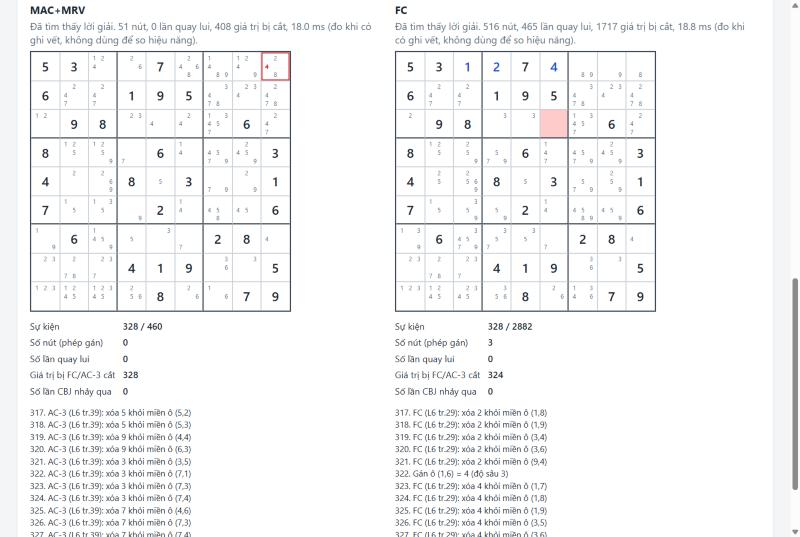

*Hình 1. MAC+MRV (trái) và FC (phải) trên đề Wikipedia, cùng ở sự kiện 328. MAC vẫn đang lan truyền AC-3 trước khi gán ô nào. FC vừa gán (1,6) = 4 thì miền của ô (3,6) bị làm rỗng (tô đỏ). Cả lượt, MAC+MRV cần 51 nút và không quay lui lần nào; FC cần 516 nút và 465 lần quay lui.*

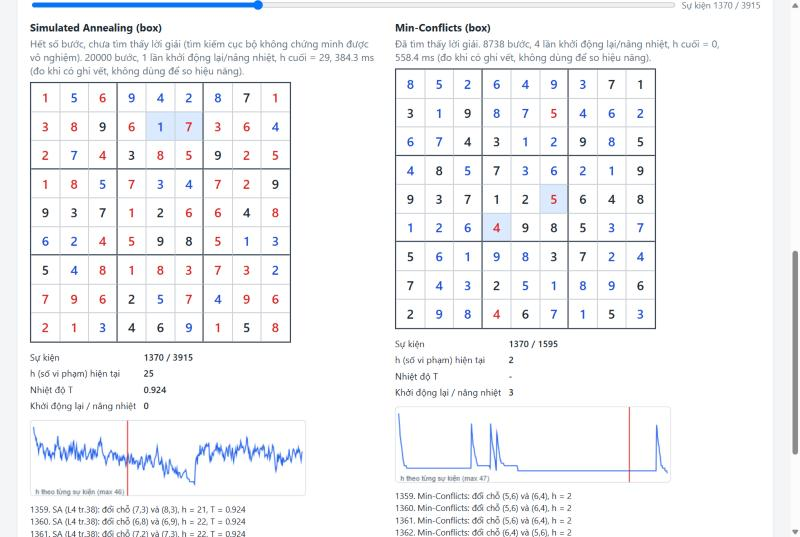

*Hình 2. SA và MC-box trên đề `g32_00` (32 ô cho sẵn), trần 20 000 bước, seed ngẫu nhiên. Đường $h$ của SA dao động vì SA nhận cả bước xấu; lượt này dừng ở $h = 29$. MC-box kẹt ở plateau $h = 2$, đổi qua lại hai ô (5,6) và (6,4), rồi khởi động lại 4 lần và giải được ở bước 8 738.*

Thời gian hiện trên giao diện được đo khi có ghi vết, nên chỉ để tham khảo. Số liệu so sánh trong mục sau lấy từ benchmark.

### Phân tích, đánh giá kết quả

Cả hai thí nghiệm chạy bằng một lệnh, hết 20.9 phút trên một máy Windows 11 (CPU Intel, Python 3.12). Bảng đủ 24 cấu hình nằm ở `results/tables.md`.

**Bảng 1.** Một số cấu hình tiêu biểu. "% kết luận" là tỷ lệ đề top95 được giải trước khi chạm trần 50 000 nút. Dấu "≥" nghĩa là quá nửa số lượt chạm trần.

| Cấu hình | top95: % kết luận | top95: trung vị số nút | top95: trung vị thời gian (ms) | top95: µs/nút | Đề 40 ô: trung vị thời gian (ms) |
|---|---:|---:|---:|---:|---:|
| BT | 23 | ≥ 50 000 | ≥ 248 | 5.5 | 0.46 |
| FC | 43 | ≥ 50 000 | ≥ 168 | 3.5 | 0.32 |
| MAC | 86 | 1 896 | 191 | 78.9 | 1.42 |
| BT+MRV | 99 | 2 184 | 140 | 67.3 | 1.56 |
| FC+MRV | 99 | 2 184 | 83 | 38.6 | 1.00 |
| MAC+MRV | 100 | 920 | 69 | 72.8 | 1.64 |
| MAC+MRV+LCV | 100 | 1 141 | 80 | 71.3 | 1.75 |
| MAC+MRV+CBJ | 100 | 798 | 61 | 72.7 | 1.67 |

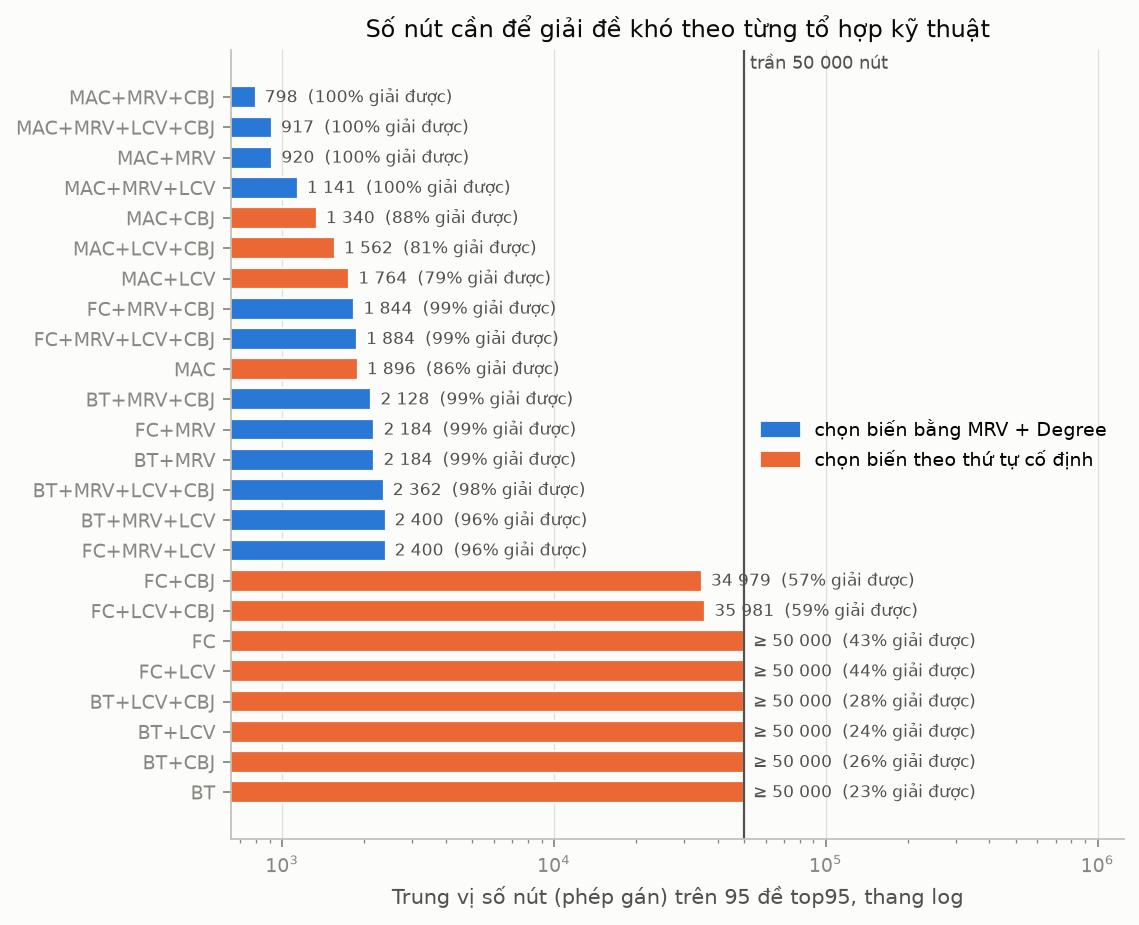

*Hình 3. Trung vị số nút của 24 cấu hình trên 95 đề top95 (thang log). Xanh: có MRV; cam: thứ tự cố định.*

**1. Thứ tự chọn biến tạo khác biệt lớn nhất (Hình 3).** Cả 12 cấu hình có MRV kết luận được ít nhất 96% số đề top95. Không có MRV thì tốt nhất chỉ đạt 88% (MAC+CBJ), còn BT thuần chỉ 23%. MRV gán trước các ô chỉ còn một giá trị và phát hiện ô hết giá trị ngay, nên cây tìm kiếm hẹp đi nhiều bậc.

**2. Suy diễn mạnh hơn thì ít nút hơn.** Xét 227 đề mà BT, FC và MAC theo thứ tự cố định đều kết luận được: trên mọi đề, số nút đều thỏa $\text{MAC} \le \text{FC} \le \text{BT}$, đúng như lý thuyết. Khi có MRV, trung vị giảm từ 2 184 nút (FC+MRV) xuống 920 nút (MAC+MRV).

**3. BT+MRV và FC+MRV duyệt đúng cùng một cây.** Trên cả 305 đề, hai cấu hình này có số nút bằng nhau tuyệt đối. Lý do như sau:

- Để chọn ô theo MRV, BT phải đếm những giá trị chưa bị láng giềng đã gán sử dụng. Đó chính là miền mà FC duy trì.
- Khi FC thấy một miền rỗng ngay sau phép gán, BT+MRV sẽ chọn đúng ô đó ở tầng sau và thất bại ngay, không tạo nút mới.

Hai thuật toán chỉ khác nhau về chi phí. FC cập nhật miền dần dần (39 µs/nút), còn BT+MRV đếm lại từ đầu ở mỗi nút (67 µs/nút).

**4. Ít nút hơn chưa chắc nhanh hơn.** Chi phí một nút chênh nhau hơn 20 lần: 3.5 µs với FC theo thứ tự cố định, 73 µs với MAC+MRV. Phần chênh chủ yếu đến từ việc MRV phải quét mọi ô trống, và MAC phải lan truyền qua hàng đợi cung. Vì vậy cấu hình nhanh nhất phụ thuộc vào độ khó của đề:

- đề 40 ô: FC theo thứ tự cố định nhanh nhất (0.32 ms), nhanh gấp 5 lần MAC+MRV;
- đề 24 ô: ngược lại, FC mất 20.8 ms còn MAC+MRV mất 8.4 ms;
- top95: FC chỉ kết luận được 43% số đề.

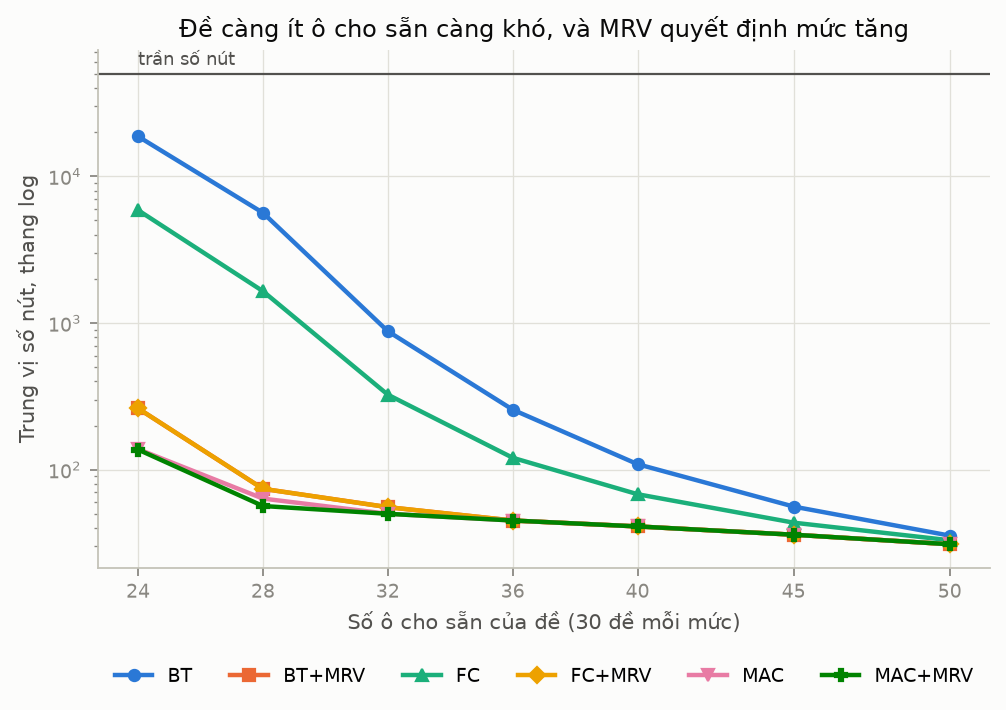

*Hình 4. Trung vị số nút theo số ô cho sẵn trên bộ tự sinh (thang log). Đường BT+MRV nằm trùng với FC+MRV, và MAC gần như trùng với MAC+MRV.*

**5. Số ô cho sẵn và độ khó (Hình 4).** Khi có MRV, mọi đề từ 45 ô trở lên và 90% đề 36 ô được giải mà không đoán sai lần nào (số nút bằng đúng số ô trống). Ở 24 ô, tỷ lệ này chỉ còn 5%. Thứ tự cố định tăng nhanh nhất: trung vị của BT tăng từ 35.5 nút ở 50 ô lên 18 715.5 nút ở 24 ô. Tuy vậy, số ô cho sẵn không phải thước đo độ khó duy nhất. Top95 có trung vị 22 ô, nhưng MAC+MRV cần 920 nút, so với 137 nút ở đề tự sinh 24 ô.

**6. LCV không ổn định.** LCV giảm số nút khi chọn biến theo thứ tự cố định trên bộ tự sinh (FC từ 121.5 xuống 102 nút). Nhưng trên top95, khi đã có MRV, LCV lại làm số nút tăng (MAC+MRV từ 920 lên 1 141). LCV chỉ đổi thứ tự thử giá trị. Đề Sudoku chuẩn có đúng một lời giải, nên cây con của mỗi giá trị sai vẫn phải duyệt hết, dù thử trước hay thử sau. Kết luận thực tế: không nên bật LCV mặc định.

**7. CBJ không bao giờ làm tệ hơn, nhưng mức lợi khác nhau.** Không có lượt kết luận được nào mà CBJ tốn nhiều nút hơn quay lui thường (Kondrak và van Beek 1997).

- Với FC theo thứ tự cố định, CBJ giảm 41% tổng số nút trên bộ tự sinh, và nâng tỷ lệ kết luận trên top95 từ 43% lên 57%.
- Với MAC+MRV, CBJ giảm 17% tổng số nút trên top95. Nhờ vậy MAC+MRV+CBJ là cấu hình tốt nhất trên top95 (798 nút, 61 ms).
- Với BT+MRV, CBJ chỉ giảm 5%. Lý do là tập xung đột của BT thô hơn: khi một ô hết giá trị, BT lấy mọi láng giềng đang giữ một giá trị trong miền của ô đó, còn FC chỉ ghi láng giềng đã xóa giá trị đó trước tiên.

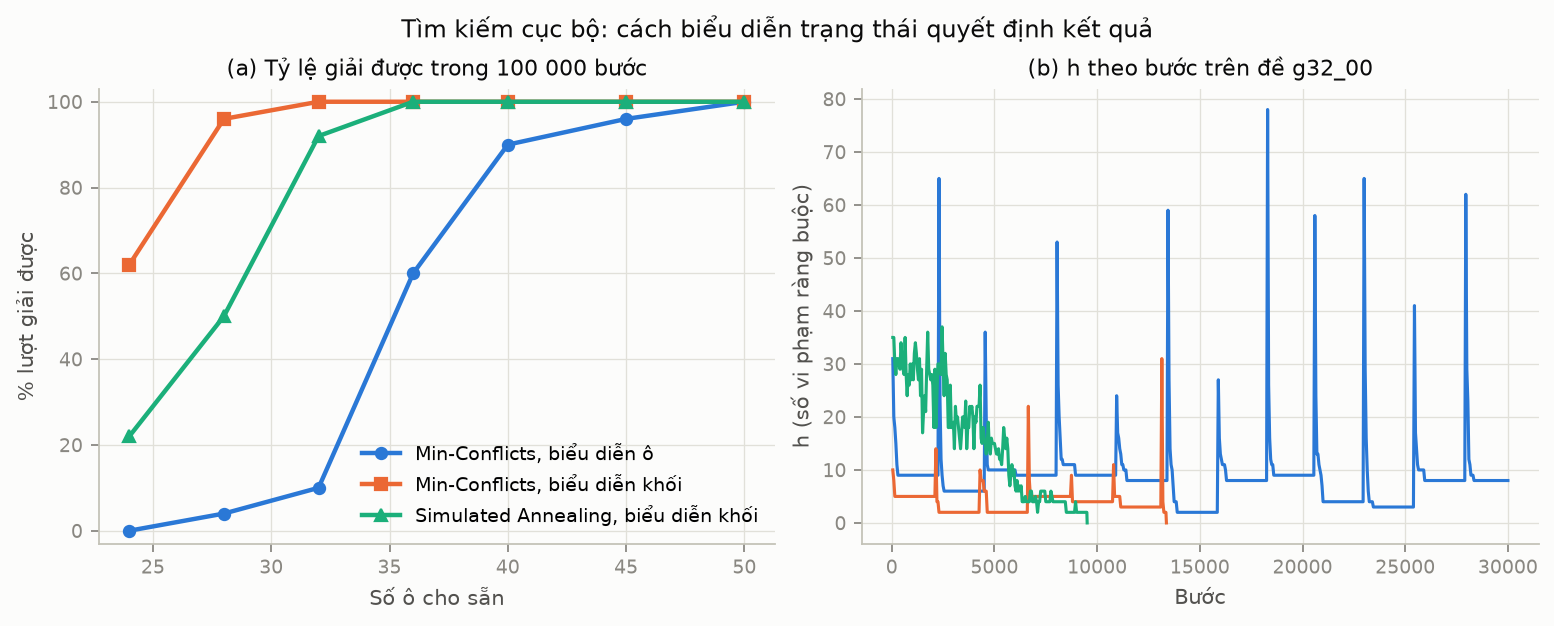

*Hình 5. (a) Tỷ lệ giải được trong 100 000 bước (10 đề mỗi mức, 5 seed mỗi đề). (b) $h$ theo bước trên đề `g32_00`, seed 0.*

**Bảng 2.** Tỷ lệ lượt giải được (%) của tìm kiếm cục bộ, mỗi ô là 50 lượt.

| Phương pháp | 50 ô | 45 ô | 40 ô | 36 ô | 32 ô | 28 ô | 24 ô | top95 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| MC-cell | 100 | 96 | 90 | 60 | 10 | 4 | 0 | 0 |
| MC-box | 100 | 100 | 100 | 100 | 100 | 96 | 62 | 2 |
| SA | 100 | 100 | 100 | 100 | 92 | 50 | 22 | 0 |

**8. Tìm kiếm cục bộ: cách biểu diễn quan trọng hơn thuật toán.**

- **Cùng Min-Conflicts, chỉ đổi biểu diễn.** Đổi từ "cell" sang "box" nâng tỷ lệ giải được từ 10% lên 100% ở 32 ô, và từ 0% lên 62% ở 24 ô. Biểu diễn "box" luôn thỏa 9 ràng buộc khối và thu nhỏ không gian tìm kiếm: một khối có 5 ô trống chỉ có $5! = 120$ cách điền thay vì $9^5 = 59\,049$. Hình 5b cho thấy MC-cell kẹt quanh $h \approx 9$, và cứ khoảng 2 000 đến 3 000 bước lại khởi động lại.
- **Cùng biểu diễn "box".** Min-Conflicts giải được nhiều hơn SA ở đề khó (62% so với 22% ở 24 ô), dù một bước của SA rẻ hơn khoảng 3.6 lần (1.9 µs so với 6.8 µs).
- **Kết quả phụ thuộc seed.** Lượt SA ở Hình 2 thất bại trên `g32_00`, còn lượt dùng seed 0 ở Hình 5b giải được sau 9 514 bước. Vì vậy mỗi đề được chạy với 5 seed.
- **So với tìm kiếm hệ thống, tìm kiếm cục bộ thua rõ.** Ở đề 24 ô, MAC+MRV giải hết với trung vị 8.4 ms, còn MC-box giải được 62% với trung vị 293 ms. Trên top95, chỉ 1 trong 150 lượt tìm kiếm cục bộ thành công.

Sudoku chuẩn có ràng buộc chặt và đúng một lời giải, nên suy diễn hiệu quả hơn. Tìm kiếm cục bộ hợp với bài toán lớn, có nhiều lời giải, như bài toán n quân hậu: theo Russell và Norvig, Min-Conflicts giải bài toán một triệu quân hậu với trung bình khoảng 50 bước.

**9. Hạn chế và hướng phát triển.**

- Chương trình viết bằng Python thuần nên thời gian tuyệt đối chậm. So sánh tương đối vẫn có nghĩa vì các cấu hình dùng chung cấu trúc dữ liệu. Thời gian mỗi lượt chỉ đo một lần nên còn nhiễu; số nút thì tất định.
- Phân rã AllDifferent thành ràng buộc nhị phân làm mất suy luận kiểu "hidden single" (số $v$ chỉ còn đặt được ở đúng một ô trong một hàng). Bước tiếp theo là thêm phù hợp cung tổng quát cho AllDifferent (Régin 1994) rồi đo lại MAC.
- Với các cấu hình yếu, trần 50 000 nút chỉ cho được cận dưới. Tìm kiếm cục bộ chỉ đo trên 10 đề mỗi mức với 5 seed, nên tỷ lệ còn sai số lớn. Có thể cải thiện tìm kiếm cục bộ bằng cách chạy AC-3 trước để thu hẹp miền, rồi chỉ cho SA đổi chỗ giữa các giá trị còn trong miền.

### Cập nhật phân công, khối lượng công việc

Nhóm chia công việc cuối kỳ thành 4 phần theo các thành phần của chương trình, giữ đúng hướng phân công đã đăng ký ở W3. Mỗi người phụ trách phần code, test và tài liệu của phần mình. Trước buổi vấn đáp, mỗi người nắm chắc các câu hỏi của phần mình trong `docs/HOI_DAP.md`.

| Thành viên | Phần phụ trách | File chính | Câu hỏi ôn (HOI_DAP) | Tỷ lệ đóng góp |
|---|---|---|---|---:|
| Nguyễn Thái An | **1. Tìm kiếm hệ thống:** mô hình CSP, trail, khung quay lui 24 cấu hình, MRV/Degree, LCV, FC, MAC/AC-3, CBJ; test so số nút theo lý thuyết | `board.py`, `csp.py`, `backtracking.py`, test tương ứng, `THUAT_TOAN.md` mục 1-7 | Mục A-D (câu 1-22) | 25% |
| Nguyễn Thanh Hải | **2. Tìm kiếm cục bộ và sinh đề:** Min-Conflicts hai cách biểu diễn, Simulated Annealing, đếm lời giải, sinh đề có nghiệm duy nhất, bộ 210 đề tự sinh và kiểm tra top95 | `local_search.py`, `generator.py`, `datasets.py`, `make_dataset.py`, `data/`, `THUAT_TOAN.md` mục 8-9 | Mục E-F (câu 23-34) | 25% |
| Trần Bình Minh | **3. Thí nghiệm và đánh giá:** thiết kế thí nghiệm, benchmark 8 520 lượt chạy, bảng và hình, phân tích kết quả, báo cáo W15, CI | `run_benchmark.py`, `plot_results.py`, `results/`, báo cáo, README, `.github/workflows/ci.yml` | Mục G (câu 35-38) và các số liệu trong báo cáo | 25% |
| Bùi Hoàng Tú | **4. Giao diện minh họa:** API FastAPI, phát lại sự kiện bằng `replay.js`, hiển thị miền giá trị từng ô, so sánh song song, biểu đồ $h$, ảnh chụp giao diện | `app/`, `test_api.py`, `test_replay_consistency.py`, `tests/js/` | Câu 39 và phần "Chương trình" của báo cáo | 25% |

Khối lượng của từng phần, tính theo repo cuối kỳ:

- **Phần 1:** khoảng 570 dòng Python.
- **Phần 2:** khoảng 590 dòng Python, kèm bộ dữ liệu 305 đề.
- **Phần 3:** khoảng 690 dòng Python, cùng kết quả đo và báo cáo.
- **Phần 4:** khoảng 1 600 dòng Python, JavaScript, HTML và CSS.

Toàn bộ có 447 test pytest và 9 test JavaScript, chạy tự động trên CI.